# Training the pix2pix de-anonymizer

One model is trained **per anonymization method**: a generator that undoes 8x8 pixelation has
learnt a different inverse than one that undoes a Gaussian blur, so `blackbar` and `pixelation`
get their own runs and their own checkpoints.

The pairs are made rather than collected. Every CelebA image is a target, and the input is that
same image with the pipeline's anonymizer applied to its detected facial area -- pixel-aligned by
construction, which is the supervision pix2pix's L1 term wants. The identities are deliberately
not the ones the experiment scores: an attacker may train on any face data, but training on
YouTube Faces would put the gallery into the generator's prior.

In [3]:
%load_ext autoreload
%autoreload 2

import logging

import torch
from matplotlib import pyplot as plt
from torch.utils.data import DataLoader

from meles.frame_aggregation.pix2pix import LOAD_SIZE, load_generator, to_image
from meles.runtime.logs import ExtraFormatter
from meles.training import AnonymizedPairs, ImageArchive, Pix2PixTrainer, Slice, checkpoint_path, split

# Not logs.configure(): that dup2s stdout and stderr into a file, which is right for a Snakemake
# job and wrong for a notebook. The formatter is the part worth reusing -- it is what turns the
# extra={...} fields the library logs into readable key=value pairs.
handler = logging.StreamHandler()
handler.setFormatter(ExtraFormatter("%(asctime)s %(levelname)-7s %(name)s | %(message)s"))
logging.basicConfig(level=logging.INFO, handlers=[handler], force=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## The images

`torchvision.datasets.CelebA` is **not** used, and not because of a download failure. Its
integrity check demands five space-separated `.txt` annotation files matching exact MD5s of the
original Google Drive upload, and one of them (`identity_CelebA.txt`) is not in the Kaggle mirror
at all -- that mirror ships `.csv` instead. Any of them missing raises
`Dataset not found or corrupted`, which reads as a broken download but means "these are not the
bytes I expected". No file location fixes it.

None of that metadata is needed here: the pairs are made from the images alone. `ImageArchive`
reads them straight out of the zip, with no extraction and no assumption about how deeply a given
mirror nested them.

In [4]:
ANONYMIZER = "pixelation"                       # the method this run attacks; one checkpoint per method
ARCHIVE = "../../data/celeba/img_align_celeba.zip"    # or a directory: ImageDirectory("data/celeba/img_align_celeba")

# SEBA's regime. Its selector takes `ids: 20` and CelebA averages 19.9 images per identity, so its
# pix2pix trains on ~340 images; its sample config's `epochs: 100` splits into 50 + 50. That is
# ~40k steps, a few minutes. See Pix2PixTraining.md before changing any of this -- the numbers
# below only make sense together, and CORPUS is the one that decides what the run costs.
CORPUS = 400                                    # images before the train/val split; None for all
BATCH_SIZE = 1                                  # upstream's default, and load-bearing: see the doc
N_EPOCHS, N_EPOCHS_DECAY = 50, 50               # SEBA passes epochs//2 for both
TRAIN_RATE = 0.85                               # SEBA's split between train and val
WORKERS = 8

train_source, val_source = split(ImageArchive(ARCHIVE), validation=1 - TRAIN_RATE)
if CORPUS is not None:
    # 'split' permutes with a fixed seed, so taking a prefix of each half is a reproducible random
    # subsample rather than whatever happened to sort first in the archive.
    train_source = Slice(train_source, range(round(CORPUS * TRAIN_RATE)))
    val_source = Slice(val_source, range(round(CORPUS * (1 - TRAIN_RATE))))

# 'load_size' turns on upstream's resize_and_crop: scale to 286, take a random 256 crop, mirror at
# random -- pix2pix's entire augmentation, drawn once per pair and applied to both ends. Off for
# validation, so that its loss is comparable between epochs rather than measured on a fresh crop.
train_pairs = AnonymizedPairs(train_source, ANONYMIZER, load_size=LOAD_SIZE, flip=True)
val_pairs = AnonymizedPairs(val_source, ANONYMIZER, load_size=None)

steps = len(train_pairs) * (N_EPOCHS + N_EPOCHS_DECAY)
print(f"{len(train_pairs)} training and {len(val_pairs)} validation images")
print(f"{steps:,} optimiser steps over {N_EPOCHS + N_EPOCHS_DECAY} epochs at batch size {BATCH_SIZE}")

2026-09-14 14:28:20,897 INFO    meles.training.sources | Read image archive path='../../data/celeba/img_align_celeba.zip' len=202599


172209 training and 30390 validation images


In [5]:
# Detect once, here in the parent process, rather than once per image per epoch in the workers.
# Roughly two minutes over CelebA on eight threads. It also gives an honest miss count -- a high
# one means the pairs are mostly whole-image anonymizations rather than face anonymizations, which
# is not the attack being modelled.
train_pairs.detect()
val_pairs.detect()

print(f"train {len(train_pairs)} pairs, {train_pairs.missing} without a detected face")
print(f"val   {len(val_pairs)} pairs, {val_pairs.missing} without a detected face")

2026-09-14 14:28:31,183 INFO    meles.weights | Downloading weights url='https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx' target='/data/projects/personal/meles/src/notebooks/models/tmp8t49dgwn.part'
Detecting (pixelation): 100%|██████████| 172209/172209 [02:26<00:00, 1173.46it/s]
2026-09-14 14:31:01,087 INFO    meles.training.pairs | Detected faces for the training pairs anonymizer='pixelation' len=172209 no_face=75
Detecting (pixelation): 100%|██████████| 30390/30390 [00:24<00:00, 1262.84it/s]
2026-09-14 14:31:25,934 INFO    meles.training.pairs | Detected faces for the training pairs anonymizer='pixelation' len=30390 no_face=17


train 172209 pairs, 75 without a detected face
val   30390 pairs, 17 without a detected face


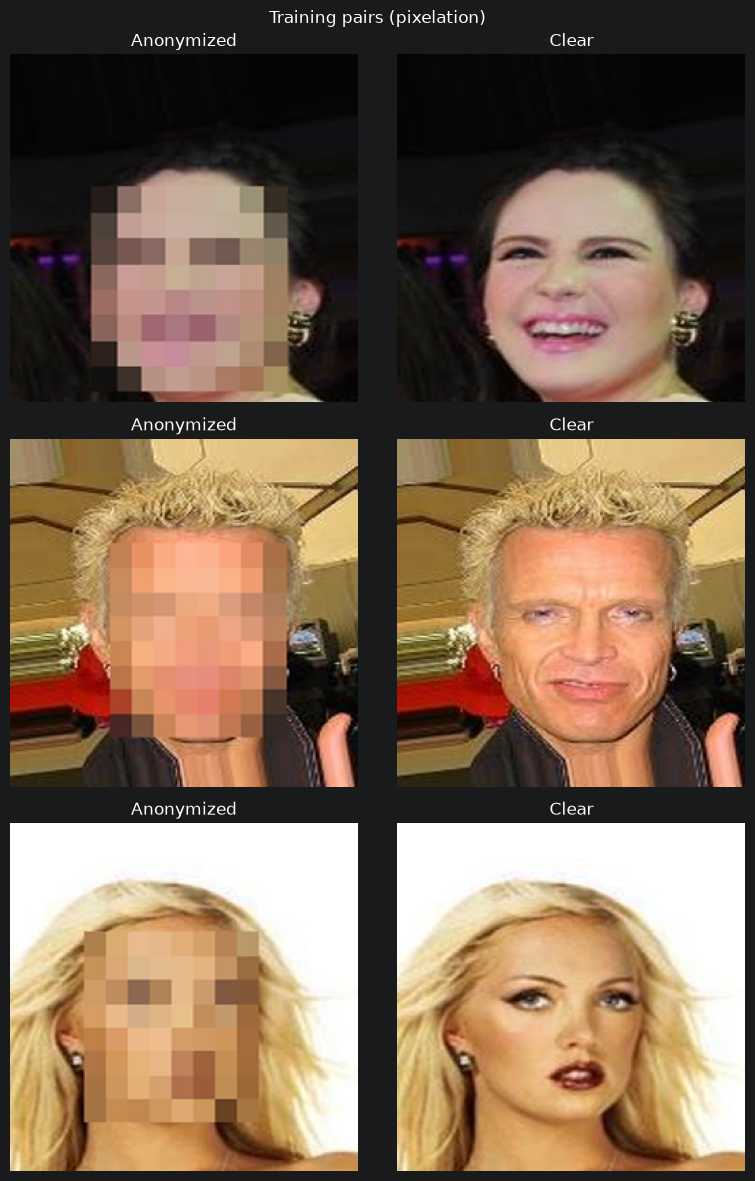

In [6]:
def show(pairs, model=None, count=3, title="Pairs"):
    """Input / target / (optionally) generated, as images rather than tensors."""
    columns = 3 if model is not None else 2
    figure, axes = plt.subplots(count, columns, figsize=(4 * columns, 4 * count), squeeze=False)
    figure.suptitle(title)

    for row in range(count):
        anonymized, clear = pairs[row]
        panels = [(anonymized, "Anonymized"), (clear, "Clear")]
        if model is not None:
            with torch.no_grad():
                device = next(model.parameters()).device
                panels.append((model(anonymized[None].to(device))[0], "Generated"))
        for column, (tensor, name) in enumerate(panels):
            # to_image returns BGR, which is what the whole pipeline speaks; matplotlib wants RGB.
            axes[row][column].imshow(to_image(tensor)[:, :, ::-1])
            axes[row][column].set_title(name)
            axes[row][column].axis("off")

    plt.tight_layout()
    plt.show()


show(train_pairs, title=f"Training pairs ({ANONYMIZER})")

## The run

`Pix2PixTrainer.resume` picks a checkpoint back up if one is there, so re-running this cell after
an interruption continues the run instead of silently restarting at epoch 0. `fit` writes the
checkpoint after every epoch.

In [7]:
# No 'drop_last': upstream's batch_size is 1, and the U-Net tolerates it because the innermost
# encoder block -- the one running at 1x1, where a BatchNorm would raise on a single sample -- is
# the one block pix2pix leaves unnormalised.
train_loader = DataLoader(
    train_pairs,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=WORKERS,
    persistent_workers=WORKERS > 0,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    val_pairs,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=WORKERS,
    persistent_workers=WORKERS > 0,
    pin_memory=torch.cuda.is_available(),
)

trainer = Pix2PixTrainer.resume(ANONYMIZER, n_epochs=N_EPOCHS, n_epochs_decay=N_EPOCHS_DECAY)
print(f"{trainer.anonymizer} on {trainer.device}, epoch {trainer.epoch}/{trainer.epochs}")

pixelation on cuda, epoch 0/200


In [8]:
def preview(trainer, epoch, every=10):
    if epoch % every == 0:
        show(val_pairs, trainer.generator, title=f"{trainer.anonymizer}, epoch {epoch}")


# No 'epochs': runs out the n_epochs + n_epochs_decay schedule. Stopping short would leave the
# learning rate part-way down its ramp, which is a different model than the schedule describes.
history = trainer.fit(
    train_loader,
    val_loader,
    on_epoch=preview,
    checkpoint=checkpoint_path(ANONYMIZER),
)

Training pixelation 1/200:  27%|██▋       | 47272/172209 [12:24<32:48, 63.46it/s]


KeyboardInterrupt: 

In [ ]:
# Read 'l1' first and the other two as diagnostics. The generator total (adversarial + 100*l1) is
# the thing being optimised but says nothing on its own: it rises whenever the discriminator pulls
# ahead, so a run whose reconstruction is steadily improving still plots as a rising curve.
panels = [
    ("l1", "Reconstruction (L1) -- the quality signal"),
    ("adv", "Generator adversarial -- how far ahead D is"),
    ("d", "Discriminator loss"),
]
figure, axes = plt.subplots(1, 3, figsize=(17, 4))
for axis, (series, title) in zip(axes, panels):
    axis.plot(history[f"train_{series}"], label="train")
    axis.plot(history[f"val_{series}"], label="validation")
    axis.set_title(title, fontsize=10)
    axis.set_xlabel("epoch")
    axis.legend()

# A discriminator that has won sits near zero while the generator's adversarial term climbs. The
# run does not fail -- L1 keeps it producing faces -- but the adversarial half has stopped
# contributing. pix2pix offers no brake for that, and SEBA runs it at its defaults.
axes[2].axhline(0.05, color="grey", linestyle=":", linewidth=1)
plt.tight_layout()
plt.show()

## Export and import

`trainer.save()` writes generator, discriminator, both optimisers and the loss history, which is
what makes a run resumable. `inference_only=True` drops everything but the generator (207 MiB
instead of 654). Either file records which anonymization it was trained against, and
`load_generator` refuses to hand back a model for a method it was not trained on -- pointing a
pixelation model at blurred frames produces plausible output and a meaningless score.

In [ ]:
path = trainer.save(checkpoint_path(ANONYMIZER).with_suffix(".generator.pt"), inference_only=True)
print(path, f"{path.stat().st_size / 1024 ** 2:.0f} MiB")

generator = load_generator(path, device=trainer.device, anonymizer=ANONYMIZER)
show(val_pairs, generator, title=f"Imported model ({ANONYMIZER})")

In [ ]:
# 'deanonymize' is the inference entry point the frame aggregator will call: frames in, frames
# out, BGR uint8, each resized back to the size it arrived at.
anonymized = [to_image(val_pairs[index][0]) for index in range(4)]
restored = generator.deanonymize(anonymized)
print([frame.shape for frame in restored])